# 01 · Análise exploratória — ENEM 2022 e 2023

**Problema.** Prever a nota média de um participante do ENEM (média de Ciências da Natureza,
Ciências Humanas, Linguagens, Matemática e Redação) usando só informações conhecidas **antes**
da prova: o questionário socioeconômico respondido na inscrição, a situação escolar, a faixa
etária e o local da prova. É um problema de **regressão**; a unidade de observação é o participante.

**Fonte.** Microdados do ENEM, INEP — <https://dados.gov.br/dados/conjuntos-dados/inep-microdados-do-enem>.
2022 é usado para treino/validação/teste e 2023 como teste temporal ("o modelo treinado num ano
funciona no ano seguinte?"). 2024 e 2025 não servem: o INEP separou questionário e notas em
arquivos sem chave em comum (Leia-Me ENEM 2024, seção 3).

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from enem import config as C, plots
from enem.plots import SERIES, INK_2, MUTED
plots.setup()
pd.set_option("display.max_columns", 50, "display.width", 160, "display.float_format", "{:,.2f}".format)

In [2]:
from enem.data import load_year
df = {2022: load_year(2022), 2023: load_year(2023)}
{y: d.shape for y, d in df.items()}

{2022: (2341913, 44), 2023: (2658763, 44)}

## 1. Filtragem dos registros

Mantemos quem esteve presente nas quatro provas objetivas e tem as cinco notas. Registros com nota 0 numa prova objetiva, mesmo com presença, são tratados como anômalos e removidos (a TRI não gera 0 para quem respondeu). Redação 0 é mantida: é um resultado previsto nas regras (fuga ao tema, texto insuficiente, em branco etc.).

In [3]:
funil = pd.DataFrame([json.loads((C.PROCESSED_DIR / f"funil_{y}.json").read_text()) for y in C.YEARS]).set_index("ano").T
funil.index = ["Inscritos", "Presentes nas 4 provas objetivas", "Com as 5 notas", "Sem nota objetiva igual a 0"]
funil["% 2022"] = 100 * funil[2022] / funil.loc["Inscritos", 2022]
funil["% 2023"] = 100 * funil[2023] / funil.loc["Inscritos", 2023]
funil.to_csv(C.TAB_DIR / "funil.csv"); funil

ano,2022,2023,% 2022,% 2023
Inscritos,3476105,3933955,100.00,100.00
Presentes nas 4 provas objetivas,2344823,2678264,67.46,68.08
Com as 5 notas,2344823,2678264,67.46,68.08
Sem nota objetiva igual a 0,2341913,2658763,67.37,67.58


## 2. Variáveis

Todas as entradas são categóricas, exceto o número de moradores (Q005). O município de residência foi retirado dos microdados pelo INEP (LGPD); usamos o **município de aplicação da prova**, que normalmente é o mesmo ou um vizinho.

In [4]:
DESCR = {
 "TP_FAIXA_ETARIA": ("Faixa etária", "ordinal (20 faixas)"),
 "TP_ST_CONCLUSAO": ("Situação de conclusão do EM", "nominal"),
 "TP_ANO_CONCLUIU": ("Anos desde a conclusão do EM (0 = não informado; 16 = 16 ou mais)", "ordinal"),
 "TP_ESCOLA": ("Tipo de escola do EM (1 = não respondeu, 2 = pública, 3 = privada)", "nominal"),
 "TP_DEPENDENCIA_ADM_ESC": ("Dependência administrativa da escola", "nominal"),
 "TP_LOCALIZACAO_ESC": ("Localização da escola (urbana/rural)", "nominal"),
 "SG_UF_PROVA": ("UF da prova", "nominal (27)"),
 "CO_MUNICIPIO_PROVA": ("Município da prova", "nominal (alta cardinalidade)"),
 "Q001": ("Escolaridade do pai/responsável", "ordinal + 'não sei'"),
 "Q002": ("Escolaridade da mãe/responsável", "ordinal + 'não sei'"),
 "Q005": ("Nº de moradores na residência", "numérica (1–20)"),
 "Q006": ("Renda familiar mensal (17 faixas)", "ordinal"),
 **{f"Q{i:03d}": ("Característica/bem da residência", "ordinal") for i in range(7, 24)},
 "Q024": ("Computador na residência", "ordinal"),
 "Q025": ("Acesso à internet", "binária"),
}
cols = C.CAT_FEATURES + C.NUM_FEATURES + [C.MUNI_FEATURE]
var = pd.DataFrame({
    "descrição": [DESCR[c][0] for c in cols],
    "tipo": [DESCR[c][1] for c in cols],
    "n_categorias": [df[2022][c].nunique() for c in cols],
    "% ausente 2022": [100 * df[2022][c].isna().mean() for c in cols],
    "% ausente 2023": [100 * df[2023][c].isna().mean() for c in cols],
}, index=cols)
var.to_csv(C.TAB_DIR / "variaveis.csv"); var

,descrição,tipo,n_categorias,% ausente 2022,% ausente 2023
TP_FAIXA_ETARIA,Faixa etária,ordinal (20 faixas),20,0.00,0.00
TP_ST_CONCLUSAO,Situação de conclusão do EM,nominal,4,0.00,0.00
TP_ANO_CONCLUIU,Anos desde a conclusão do EM (0 = não informad...,ordinal,17,0.00,0.00
TP_ESCOLA,"Tipo de escola do EM (1 = não respondeu, 2 = p...",nominal,3,0.00,0.00
TP_DEPENDENCIA_ADM_ESC,Dependência administrativa da escola,nominal,4,70.45,73.03
TP_LOCALIZACAO_ESC,Localização da escola (urbana/rural),nominal,2,70.45,73.03
SG_UF_PROVA,UF da prova,nominal (27),27,0.00,0.00
Q001,Escolaridade do pai/responsável,ordinal + 'não sei',8,0.00,0.00
Q002,Escolaridade da mãe/responsável,ordinal + 'não sei',8,0.00,0.00
Q006,Renda familiar mensal (17 faixas),ordinal,17,0.00,0.00


### 2.1 Valores ausentes e respostas "não informativas"

O questionário não tem valores ausentes entre os presentes. A ausência relevante é **estrutural**:
os campos da escola (`TP_DEPENDENCIA_ADM_ESC`, `TP_LOCALIZACAO_ESC`) só são preenchidos para quem
conclui o ensino médio no ano da prova. Além disso, há categorias que funcionam como ausência
("não respondeu" em `TP_ESCOLA`, "não sei" em Q001/Q002). Em vez de imputar, mantemos a ausência como uma
**categoria própria** no one-hot: o fato de não saber ou não responder também carrega informação.

In [5]:
nao_info = pd.DataFrame({
  y: {"TP_ESCOLA = não respondeu": 100 * (d["TP_ESCOLA"] == 1).mean(),
      "Escola (dependência adm.) ausente": 100 * d["TP_DEPENDENCIA_ADM_ESC"].isna().mean(),
      "Q001 = não sei (pai)": 100 * (d["Q001"] == "H").mean(),
      "Q002 = não sei (mãe)": 100 * (d["Q002"] == "H").mean(),
      "TP_ANO_CONCLUIU = não informado": 100 * (d["TP_ANO_CONCLUIU"] == 0).mean()}
  for y, d in df.items()})
nao_info.round(1)

,2022,2023
TP_ESCOLA = não respondeu,59.20,60.70
Escola (dependência adm.) ausente,70.40,73.00
Q001 = não sei (pai),8.60,9.30
Q002 = não sei (mãe),2.70,2.90
TP_ANO_CONCLUIU = não informado,62.30,62.30


In [6]:
d = df[2022]
print("TP_ESCOLA por situação de conclusão (2022, % na linha):")
pd.crosstab(d["TP_ST_CONCLUSAO"], d["TP_ESCOLA"], normalize="index").mul(100).round(1)

TP_ESCOLA por situação de conclusão (2022, % na linha):


TP_ESCOLA,1,2,3
TP_ST_CONCLUSAO,,,
1,100.00,0.00,0.00
2,0.00,79.40,20.60
3,100.00,0.00,0.00
4,100.00,0.00,0.00


### 2.2 Duplicados

Cada linha é uma inscrição. Verificamos (a) linhas idênticas em entradas **e** notas, que indicariam registro duplicado, e (b) participantes com o mesmo perfil de entrada. Pessoas com o mesmo perfil e notas diferentes mostram o erro irredutível: nenhum modelo acerta duas notas diferentes para entradas idênticas.

In [7]:
feat = C.CAT_FEATURES + C.NUM_FEATURES + [C.MUNI_FEATURE]
d = df[2022]
dup_full = d.duplicated(subset=feat + C.GRADE_COLS).sum()
dup_x = d.duplicated(subset=feat).sum()
print(f"linhas duplicadas (entradas + 5 notas): {dup_full:,}")
print(f"linhas com perfil de entrada repetido:  {dup_x:,} ({100*dup_x/len(d):.1f}%)")
# ruído irredutível estimado: variância do alvo DENTRO de perfis idênticos (perfis com >= 5 pessoas)
g = d.groupby(feat, observed=True)[C.TARGET]
stats_g = g.agg(["count", "var"])
big = stats_g[stats_g["count"] >= 5]
print(f"perfis com >=5 participantes: {len(big):,} grupos, {big['count'].sum():,} pessoas")
print(f"desvio-padrão médio da nota dentro do mesmo perfil: {np.sqrt(np.average(big['var'], weights=big['count'])):.1f} pontos")

linhas duplicadas (entradas + 5 notas): 0
linhas com perfil de entrada repetido:  17,289 (0.7%)


perfis com >=5 participantes: 498 grupos, 5,259 pessoas
desvio-padrão médio da nota dentro do mesmo perfil: 72.6 pontos


## 3. Variável alvo: nota média

`NOTA_MEDIA` = média simples das 5 notas (escala ENEM, em pontos). As quatro provas objetivas usam a TRI (escala com média 500 e desvio 100 na referência de 2009); a redação vai de 0 a 1000.

In [8]:
from scipy import stats
def resumo(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return pd.Series({"n": len(s), "média": s.mean(), "desvio": s.std(), "mín": s.min(), "p1": s.quantile(.01),
        "p25": q1, "mediana": s.median(), "p75": q3, "p99": s.quantile(.99), "máx": s.max(),
        "assimetria": stats.skew(s), "curtose (excesso)": stats.kurtosis(s),
        "% fora 1,5·IQR": 100 * ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).mean()})
alvo = pd.DataFrame({y: resumo(d[C.TARGET]) for y, d in df.items()})
alvo.to_csv(C.TAB_DIR / "alvo_resumo.csv"); alvo

,2022,2023
n,"2,341,913.00","2,658,763.00"
média,543.73,542.43
desvio,87.75,92.96
mín,254.62,246.44
p1,332.32,325.68
p25,484.72,477.18
mediana,540.68,540.06
p75,602.14,606.88
p99,749.92,752.80
máx,855.98,862.58


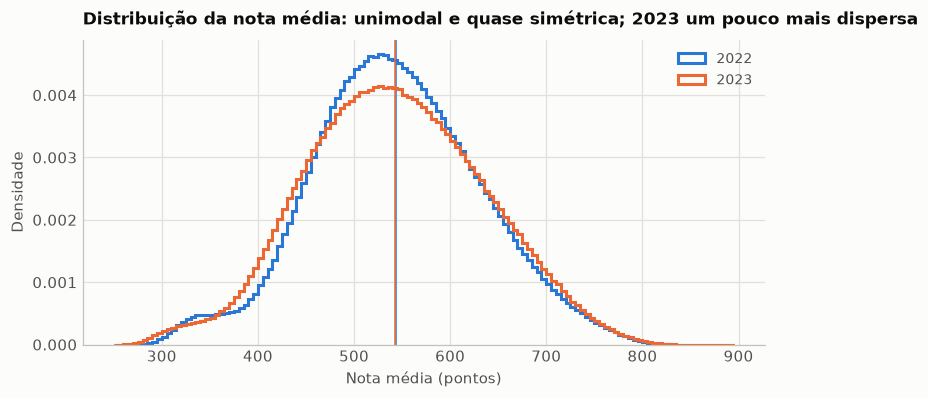

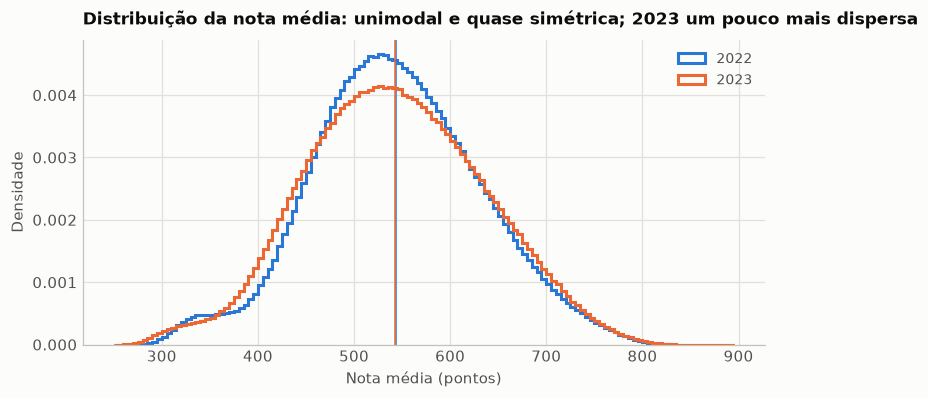

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(250, 900, 5)
for i, (y, d) in enumerate(df.items()):
    ax.hist(d[C.TARGET], bins=bins, histtype="step", linewidth=2, color=SERIES[i], density=True, label=str(y))
    ax.axvline(d[C.TARGET].mean(), color=SERIES[i], linewidth=1)
ax.set_xlabel("Nota média (pontos)"); ax.set_ylabel("Densidade")
ax.set_title("Distribuição da nota média: unimodal e quase simétrica; 2023 um pouco mais dispersa")
ax.legend(); plots.save(fig, "eda_alvo_hist")

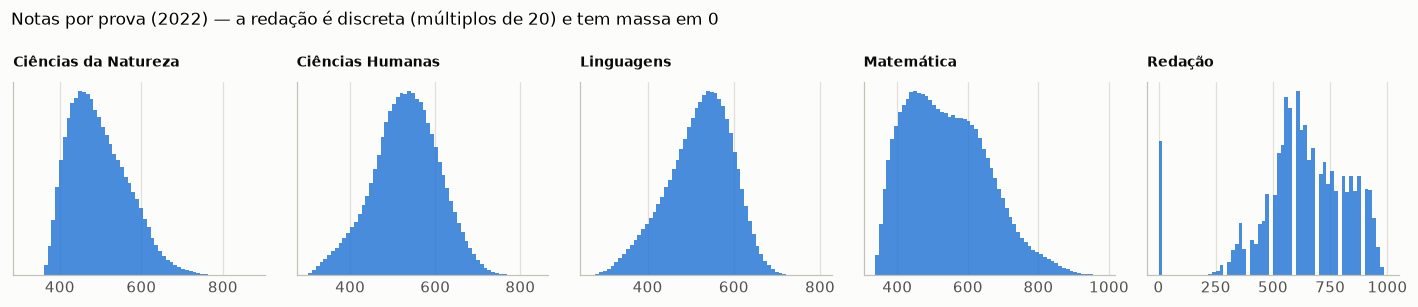

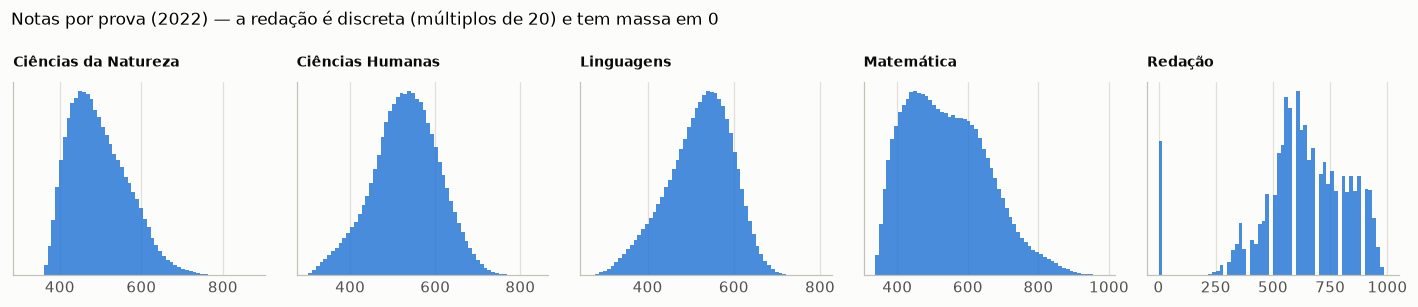

In [10]:
nomes = {"NU_NOTA_CN": "Ciências da Natureza", "NU_NOTA_CH": "Ciências Humanas", "NU_NOTA_LC": "Linguagens",
         "NU_NOTA_MT": "Matemática", "NU_NOTA_REDACAO": "Redação"}
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8), sharey=False)
for ax, c in zip(axes, C.GRADE_COLS):
    ax.hist(df[2022][c], bins=60, color=SERIES[0], alpha=.85)
    ax.set_title(nomes[c], fontsize=9); ax.set_yticks([])
fig.suptitle("Notas por prova (2022) — a redação é discreta (múltiplos de 20) e tem massa em 0", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plots.save(fig, "eda_notas_por_prova")

In [11]:
corr = df[2022][C.GRADE_COLS].corr().rename(index=nomes, columns=nomes)
print("Correlação entre as cinco notas (2022) — todas positivas e moderadas a altas, o que justifica um alvo agregado:")
corr.round(2)

Correlação entre as cinco notas (2022) — todas positivas e moderadas a altas, o que justifica um alvo agregado:


,Ciências da Natureza,Ciências Humanas,Linguagens,Matemática,Redação
Ciências da Natureza,1.00,0.61,0.57,0.60,0.43
Ciências Humanas,0.61,1.00,0.74,0.63,0.50
Linguagens,0.57,0.74,1.00,0.59,0.50
Matemática,0.60,0.63,0.59,1.00,0.48
Redação,0.43,0.50,0.50,0.48,1.00


In [12]:
red0 = {y: 100 * (d["NU_NOTA_REDACAO"] == 0).mean() for y, d in df.items()}
print("% com redação = 0:", {k: round(v, 2) for k, v in red0.items()})
df[2022].loc[df[2022]["NU_NOTA_REDACAO"] == 0, "TP_STATUS_REDACAO"].value_counts()

% com redação = 0: {2022: np.float64(4.21), 2023: np.float64(3.37)}


TP_STATUS_REDACAO
4.00    37506
6.00    26466
3.00    23929
8.00     6857
2.00     1668
9.00     1405
7.00      680
Name: count, dtype: int64

## 4. Relação entre entradas e alvo

Medimos a força de cada variável sozinha pela **razão de correlação η²** (fração da variância do alvo explicada pelas médias por categoria). É uma medida univariada: não considera redundância entre variáveis.

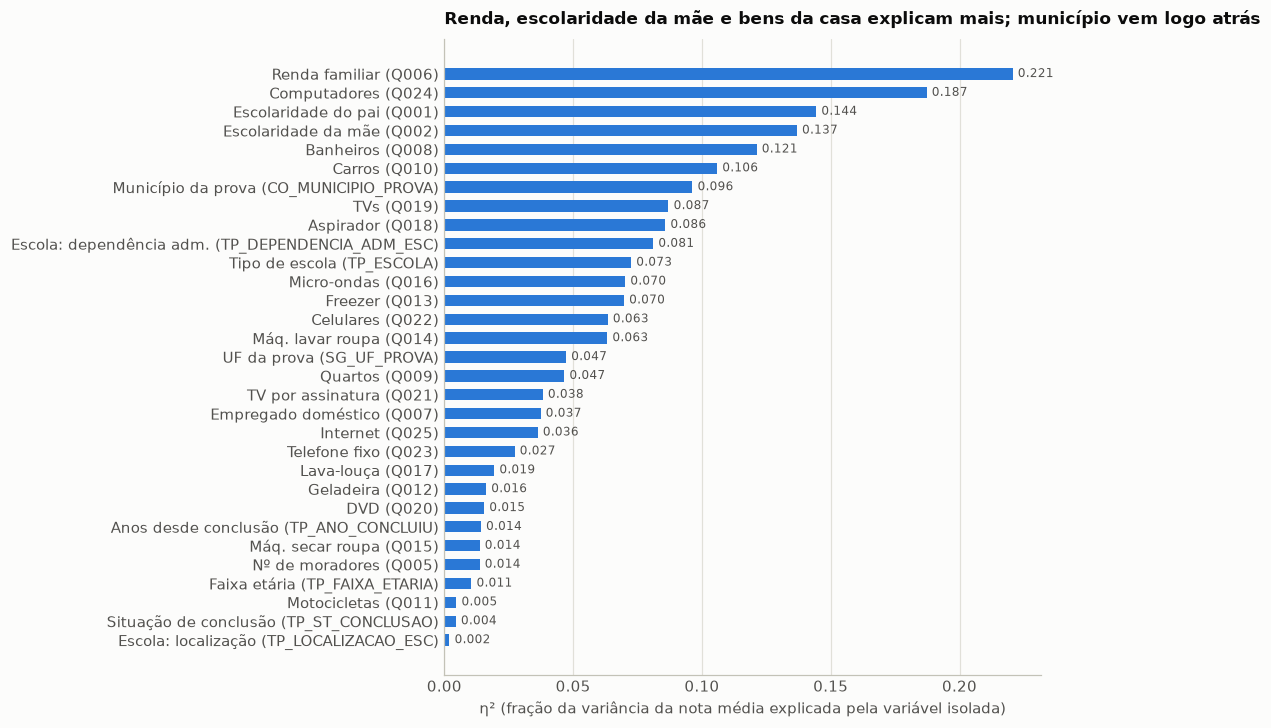

In [13]:
def eta2(x, y):
    g = pd.DataFrame({"x": x.astype("string").fillna("NA"), "y": y}).groupby("x")["y"]
    return float((g.count() * (g.mean() - y.mean())**2).sum() / ((y - y.mean())**2).sum())
d = df[2022]
ROTULO = {"Q001": "Escolaridade do pai", "Q002": "Escolaridade da mãe", "Q005": "Nº de moradores", "Q006": "Renda familiar",
  "Q007": "Empregado doméstico", "Q008": "Banheiros", "Q009": "Quartos", "Q010": "Carros", "Q011": "Motocicletas",
  "Q012": "Geladeira", "Q013": "Freezer", "Q014": "Máq. lavar roupa", "Q015": "Máq. secar roupa", "Q016": "Micro-ondas",
  "Q017": "Lava-louça", "Q018": "Aspirador", "Q019": "TVs", "Q020": "DVD", "Q021": "TV por assinatura", "Q022": "Celulares",
  "Q023": "Telefone fixo", "Q024": "Computadores", "Q025": "Internet", "TP_FAIXA_ETARIA": "Faixa etária",
  "TP_ST_CONCLUSAO": "Situação de conclusão", "TP_ANO_CONCLUIU": "Anos desde conclusão", "TP_ESCOLA": "Tipo de escola",
  "TP_DEPENDENCIA_ADM_ESC": "Escola: dependência adm.", "TP_LOCALIZACAO_ESC": "Escola: localização",
  "SG_UF_PROVA": "UF da prova", "CO_MUNICIPIO_PROVA": "Município da prova"}
rank = pd.Series({c: eta2(d[c], d[C.TARGET]) for c in feat}).sort_values()
fig, ax = plt.subplots(figsize=(7, 7.5))
ax.barh([f"{ROTULO[c]} ({c})" for c in rank.index], rank.values, height=0.6, color=SERIES[0])
for i, v in enumerate(rank.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("η² (fração da variância da nota média explicada pela variável isolada)")
ax.set_title("Renda, escolaridade da mãe e bens da casa explicam mais; município vem logo atrás")
ax.grid(axis="y", visible=False); plots.save(fig, "eda_eta2")
rank.sort_values(ascending=False).to_csv(C.TAB_DIR / "eta2.csv")

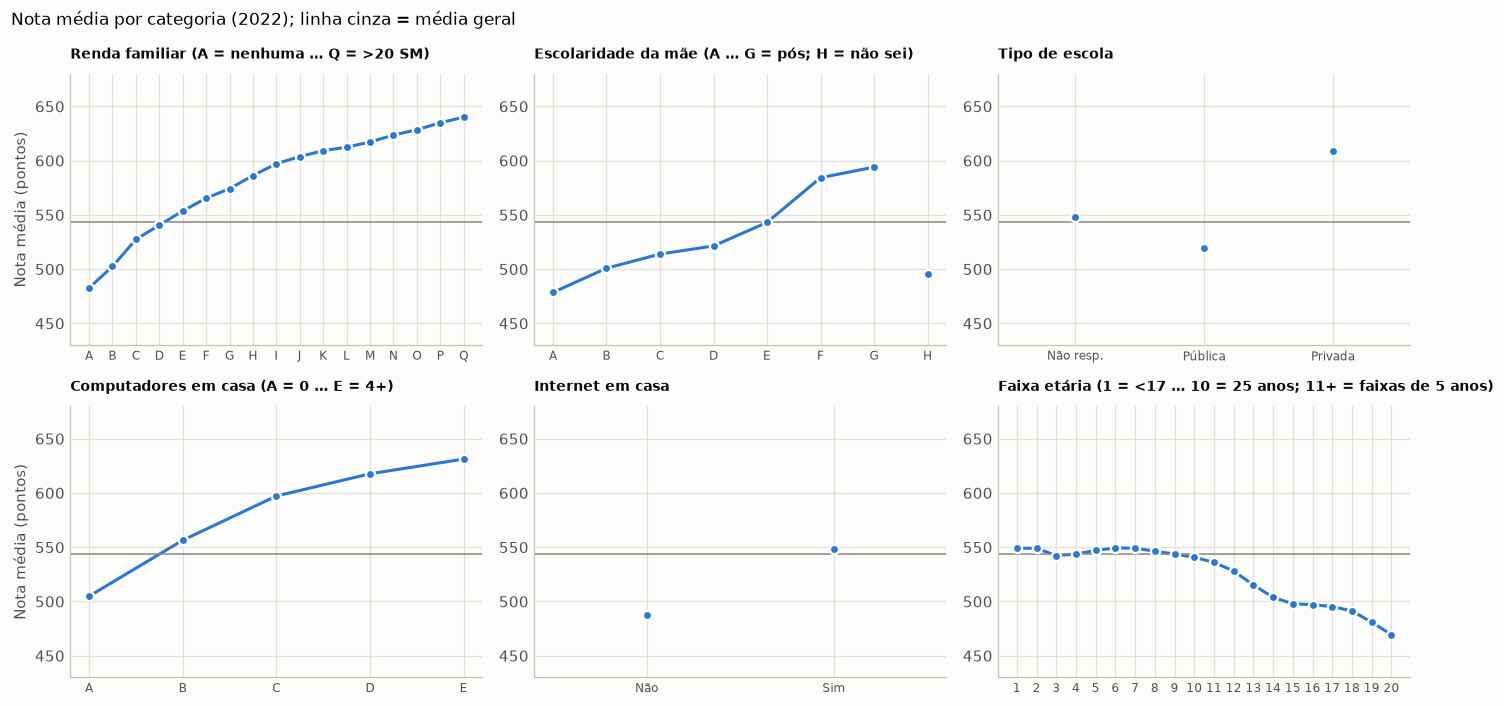

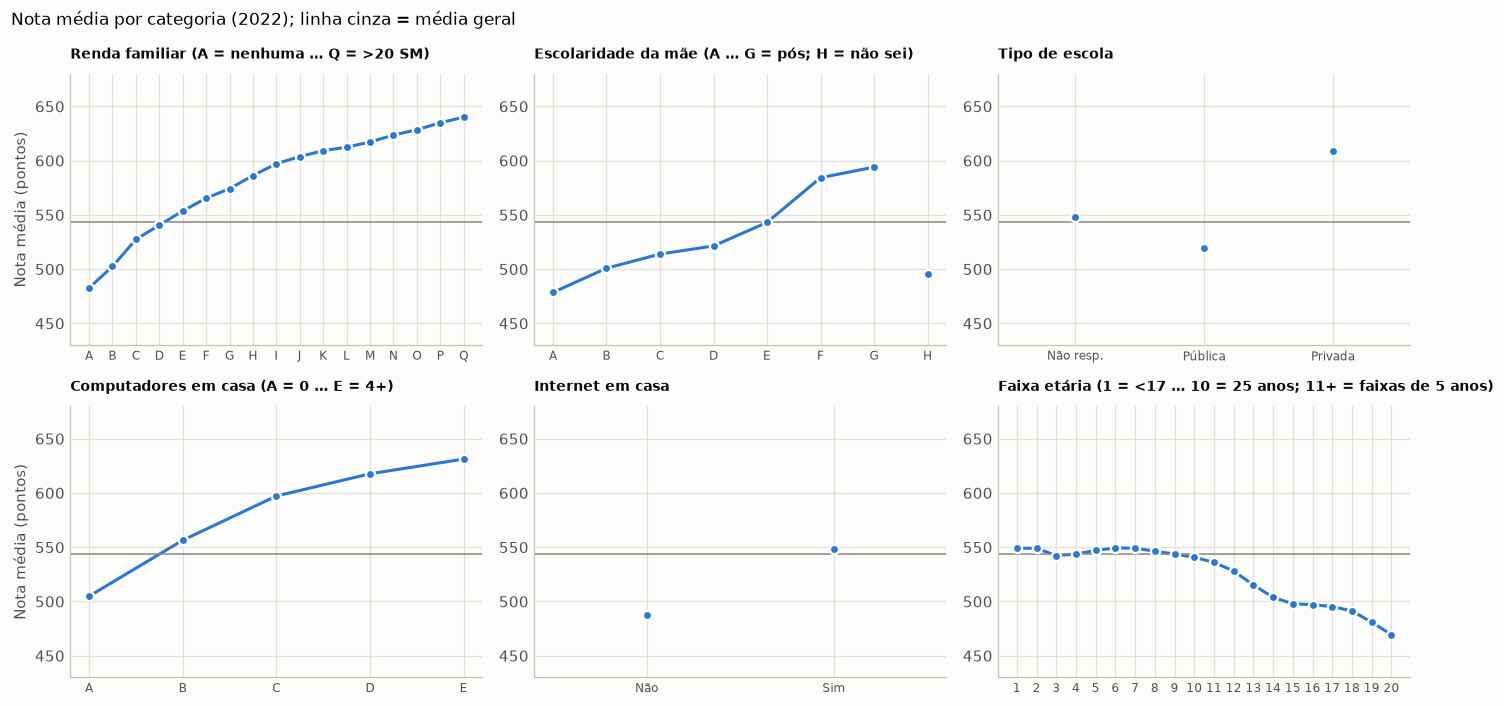

In [14]:
def media_por(col, ordem=None, rotulos=None):
    g = df[2022].groupby(col, observed=True)[C.TARGET].agg(["mean", "count"])
    if ordem is not None: g = g.reindex(ordem)
    if rotulos is not None: g.index = rotulos
    return g

paineis = [  # (coluna, título, ordem, rótulos, ordinal?)
    ("Q006", "Renda familiar (A = nenhuma … Q = >20 SM)", None, None, True),
    ("Q002", "Escolaridade da mãe (A … G = pós; H = não sei)", None, None, True),
    ("TP_ESCOLA", "Tipo de escola", [1, 2, 3], ["Não resp.", "Pública", "Privada"], False),
    ("Q024", "Computadores em casa (A = 0 … E = 4+)", None, None, True),
    ("Q025", "Internet em casa", ["A", "B"], ["Não", "Sim"], False),
    ("TP_FAIXA_ETARIA", "Faixa etária (1 = <17 … 10 = 25 anos; 11+ = faixas de 5 anos)", list(range(1, 21)), None, True),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, titulo, ordem, rot, ordinal) in zip(axes.flat, paineis):
    g = media_por(col, ordem, rot)
    x = np.arange(len(g))
    # "não sei" (H) não é um nível da escala: fica como ponto solto
    n_linha = len(g) - 1 if col == "Q002" else len(g)
    if ordinal:
        ax.plot(x[:n_linha], g["mean"].values[:n_linha], color=SERIES[0], linewidth=2)
    ax.scatter(x, g["mean"], s=36, color=SERIES[0], edgecolor=plots.SURFACE, linewidth=1.5, zorder=3)
    ax.set_xticks(x, [str(i) for i in g.index], fontsize=8)
    ax.set_title(titulo, fontsize=9); ax.set_ylim(430, 680)
    if not ordinal: ax.set_xlim(-0.6, len(g) - 0.4)
    ax.axhline(df[2022][C.TARGET].mean(), color=MUTED, linewidth=1)
axes[0, 0].set_ylabel("Nota média (pontos)"); axes[1, 0].set_ylabel("Nota média (pontos)")
fig.suptitle("Nota média por categoria (2022); linha cinza = média geral", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plots.save(fig, "eda_media_por_categoria")

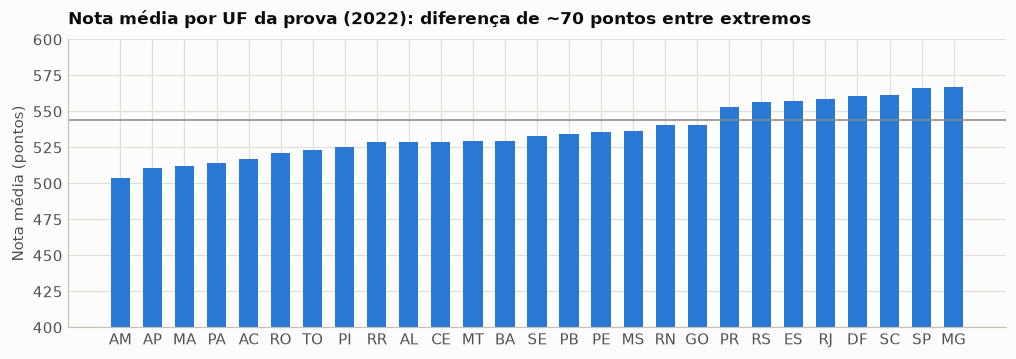

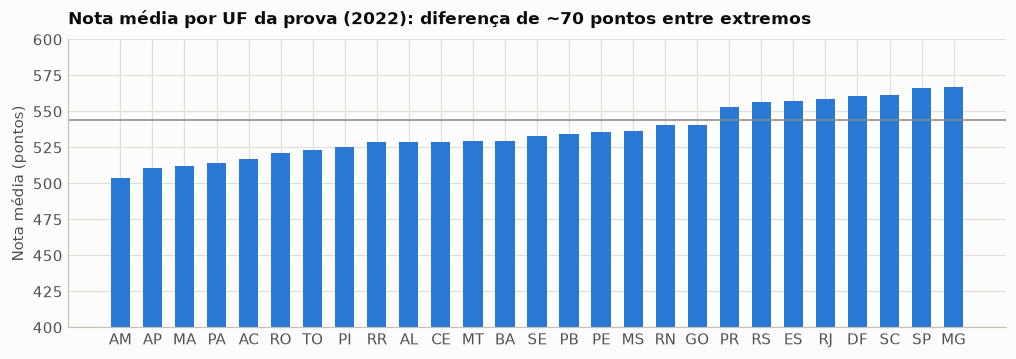

In [15]:
uf = df[2022].groupby("SG_UF_PROVA")[C.TARGET].agg(["mean", "count"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(uf.index, uf["mean"] - 400, bottom=400, width=0.6, color=SERIES[0])
ax.axhline(df[2022][C.TARGET].mean(), color=MUTED, linewidth=1)
ax.set_ylabel("Nota média (pontos)"); ax.set_ylim(400, 600)
ax.set_title("Nota média por UF da prova (2022): diferença de ~70 pontos entre extremos")
plots.save(fig, "eda_media_por_uf")

### 4.1 Município

O ENEM é aplicado em ~1,75 mil municípios. A camada de **embedding** aprende um vetor por município (municípios com menos de 30 participantes no treino caem numa categoria única "raro/novo"). A variação entre municípios é grande mesmo dentro da mesma UF, o que justifica usar o município além da UF.

In [16]:
m = df[2022].groupby(C.MUNI_FEATURE).agg(n=(C.TARGET, "size"), media=(C.TARGET, "mean"), uf=("SG_UF_PROVA", "first"))
print(f"municípios: {len(m):,}; com >=30 participantes: {(m['n']>=30).sum():,} ({100*m.loc[m['n']>=30,'n'].sum()/m['n'].sum():.2f}% dos participantes)")
print("participantes por município (quantis):", m["n"].quantile([.1,.25,.5,.75,.9,.99]).round(0).to_dict())
dentro_uf = m[m["n"] >= 30].groupby("uf")["media"].agg(lambda s: s.max() - s.min())
print(f"amplitude média da nota entre municípios de uma mesma UF: {dentro_uf.mean():.0f} pontos")

municípios: 1,747; com >=30 participantes: 1,745 (100.00% dos participantes)
participantes por município (quantis): {0.1: 196.0, 0.25: 315.0, 0.5: 570.0, 0.75: 1090.0, 0.9: 2257.0, 0.99: 13640.0}
amplitude média da nota entre municípios de uma mesma UF: 75 pontos


## 5. Mudança de distribuição entre 2022 e 2023

O teste em 2023 avalia se o modelo continua válido no ano seguinte. As notas da TRI são equalizadas entre anos, mas a redação e a composição dos participantes mudam. Comparamos as médias e a **distância de variação total** (TVD, 0 = distribuições iguais, 1 = disjuntas) de cada entrada.

In [17]:
comp = pd.DataFrame({y: d[C.GRADE_COLS + [C.TARGET]].mean() for y, d in df.items()})
comp["diferença"] = comp[2023] - comp[2022]; comp

,2022,2023,diferença
NU_NOTA_CN,496.13,498.97,2.84
NU_NOTA_CH,530.50,527.11,-3.39
NU_NOTA_LC,520.09,520.77,0.69
NU_NOTA_MT,542.76,537.37,-5.40
NU_NOTA_REDACAO,629.16,627.91,-1.25
NOTA_MEDIA,543.73,542.43,-1.30


In [18]:
def tvd(a, b):
    pa = a.astype("string").fillna("NA").value_counts(normalize=True)
    pb = b.astype("string").fillna("NA").value_counts(normalize=True)
    return 0.5 * pa.subtract(pb, fill_value=0).abs().sum()
shift = pd.Series({c: tvd(df[2022][c], df[2023][c]) for c in feat}).sort_values(ascending=False)
shift.head(10).round(3)

Q024                 0.06
Q006                 0.05
Q020                 0.04
Q023                 0.04
Q010                 0.03
Q019                 0.03
Q009                 0.03
CO_MUNICIPIO_PROVA   0.03
Q016                 0.03
Q022                 0.03
dtype: float64

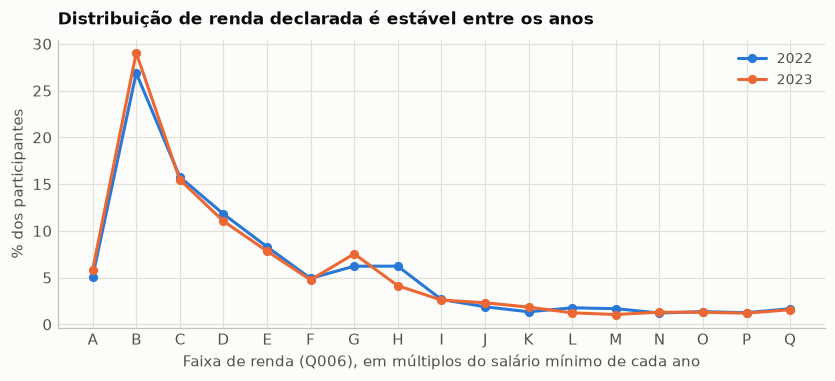

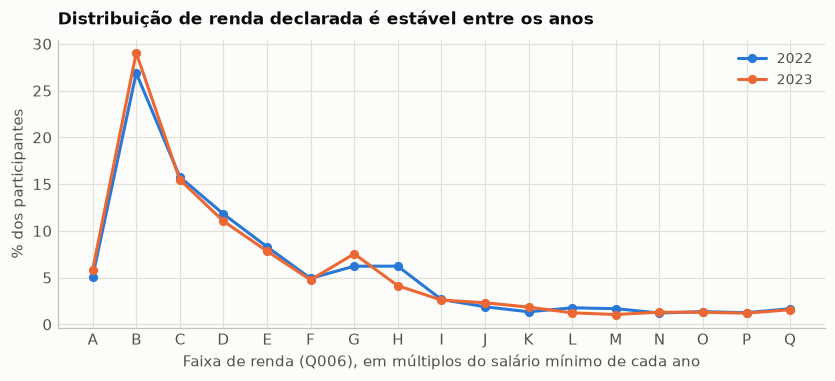

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.4))
letras = list("ABCDEFGHIJKLMNOPQ")
for i, (y, d) in enumerate(df.items()):
    p = d["Q006"].value_counts(normalize=True).reindex(letras).fillna(0) * 100
    ax.plot(range(len(letras)), p.values, marker="o", color=SERIES[i], label=str(y))
ax.set_xticks(range(len(letras)), letras); ax.set_ylabel("% dos participantes")
ax.set_xlabel("Faixa de renda (Q006), em múltiplos do salário mínimo de cada ano")
ax.set_title("Distribuição de renda declarada é estável entre os anos"); ax.legend()
plots.save(fig, "eda_renda_2022_2023")

## 6. Risco de vazamento e variáveis excluídas

| Variável | Motivo da exclusão |
|---|---|
| `NU_NOTA_*`, `NU_NOTA_COMP*` | compõem o alvo |
| `TX_RESPOSTAS_*`, `TX_GABARITO_*` | respostas e gabaritos da própria prova |
| `TP_PRESENCA_*`, `TP_STATUS_REDACAO` | só existem depois da prova (e definem o filtro) |
| `CO_PROVA_*` | cor do caderno, definida no dia da prova |
| `TP_SEXO`, `TP_COR_RACA` | conhecidas antes da prova, mas deixadas de fora de propósito para não usar atributos protegidos como preditores; são usadas só na **análise de erro por grupo** |
| `Q003`, `Q004`, `TP_LINGUA`, `TP_ESTADO_CIVIL` | conhecidas antes da prova, mas fora do escopo definido (ver relatório) |

Todas as entradas usadas vêm da ficha de inscrição, preenchida meses antes da prova.

## 7. Conclusões da análise exploratória

- ~2,34 milhões de participantes válidos em 2022 e ~2,66 milhões em 2023; não há ausências no questionário,
  só ausência estrutural nos campos da escola, tratada como categoria própria.
- O alvo é unimodal e quase simétrico (assimetria ≈ 0,05, curtose ≈ 0), e só ~0,5% das notas fica fora de 1,5·IQR. Esses
  valores extremos são notas reais (redação 0, notas máximas), não erros de registro, e são mantidos.
- 4,2% dos participantes de 2022 tiraram 0 na redação (em branco, fuga ao tema, cópia do texto motivador). Isso puxa a nota
  média para baixo de um jeito que o perfil socioeconômico dificilmente prevê.
- Renda, escolaridade dos pais, bens da residência e local da prova são os sinais mais fortes; cada um sozinho explica até ~20% da variância.
- Só 0,7% dos participantes repetem exatamente o perfil de entrada (o questionário tem muitas combinações), mas, nos perfis
  repetidos, a nota varia ~73 pontos (desvio-padrão) entre pessoas idênticas para o modelo. O **erro irredutível é grande**,
  então não se deve esperar R² perto de 1 com informação socioeconômica.